# 04 · Churn Prediction, Drivers & Revenue Impact

### Defining churn in a non-subscription business
Retail customers never "cancel", they just stop buying. So churn is defined as:

> A customer who bought in the 12 months before a cutoff date and makes
> **no purchase in the 90 days after** it.

### Avoiding leakage
- Features use **only** transactions before the cutoff; labels use only the 90 days after.
- Training uses 4 quarterly snapshots (Sep-2010 → Jun-2011).
- Testing uses a **later, unseen snapshot** (cutoff 2011-09-10), i.e. an
  out-of-time test, which mimics how the model would be used in production.
- Final risk scores are produced as of 2011-12-10 for the dashboard.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report,
                             roc_auc_score, roc_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from src import config as C
from src import features as F
from src import io
from src import viz
from src.viz import PALETTE

warnings.filterwarnings("ignore")
viz.set_style()
t = io.load_all()
sales, returns, products = t["sales"], t["returns"], t["products"]

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Build snapshot datasets

In [2]:
def build_snapshot(cutoff):
    X = F.churn_features(sales, returns, products, cutoff)
    X["churned"] = F.churn_labels(sales, X.index, cutoff)
    X["future_spend_90d"] = F.future_spend(sales, X.index, cutoff)
    return X

train = pd.concat([build_snapshot(c) for c in C.TRAIN_SNAPSHOTS])
test = build_snapshot(C.TEST_SNAPSHOT)

summary = (pd.concat([train, test])
           .groupby("snapshot")
           .agg(customers=("churned", "size"), churn_rate=("churned", "mean")))
summary["set"] = ["train"] * len(C.TRAIN_SNAPSHOTS) + ["test"]
summary.style.format({"churn_rate": "{:.1%}"})

,customers,churn_rate,set
snapshot,,,
2010-09-10 00:00:00,3351,42.4%,train
2010-12-10 00:00:00,4223,68.9%,train
2011-03-11 00:00:00,4279,63.2%,train
2011-06-10 00:00:00,4323,64.2%,train
2011-09-10 00:00:00,4306,49.3%,test


Churn is seasonal: snapshots taken just before the Q4 gifting season (Sep)
show lower churn because most customers come back to stock up for Christmas.

In [3]:
FEATURES = [c for c in train.columns if c not in ("snapshot", "churned", "future_spend_90d")]
X_train, y_train = train[FEATURES], train["churned"]
X_test, y_test = test[FEATURES], test["churned"]
print(f"{len(FEATURES)} features:", FEATURES)

26 features: ['recency_days', 'tenure_days', 'frequency', 'monetary', 'avg_order_value', 'avg_items_per_order', 'avg_lines_per_order', 'avg_gap_days', 'std_gap_days', 'orders_last_30d', 'spend_last_30d', 'orders_last_90d', 'spend_last_90d', 'orders_last_180d', 'spend_last_180d', 'orders_last_365d', 'spend_last_365d', 'spend_prev_90d', 'spend_trend', 'recency_vs_gap', 'distinct_products', 'distinct_categories', 'seasonal_spend_share', 'return_rate', 'is_uk', 'days_to_dec1']


## 2. Models
1. **Naive rule:** churn if no order in the last 90 days (what a business would do without a model).
2. **Logistic regression:** interpretable baseline (log-transformed, scaled).
3. **LightGBM:** gradient-boosted trees capture non-linear behaviour.

In [4]:
naive_score = (X_test["recency_days"] > 90).astype(int)

skewed = lambda X: np.sign(X) * np.log1p(np.abs(X))
logreg = make_pipeline(FunctionTransformer(skewed), StandardScaler(),
                       LogisticRegression(max_iter=2000, C=0.5))
logreg.fit(X_train, y_train)

# Model selection without touching the test set: leave-one-snapshot-out CV on
# the 4 training snapshots. Deeper trees fit the training data better but
# generalise worse across seasons, so a shallow, regularised model wins.
def lgbm_with(leaves, min_child):
    return lgb.LGBMClassifier(n_estimators=500, learning_rate=0.02, num_leaves=leaves,
                              min_child_samples=min_child, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, reg_lambda=5.0,
                              random_state=C.RANDOM_STATE, verbose=-1)

grid = {}
for leaves, min_child in [(31, 20), (15, 40), (7, 100), (4, 200)]:
    fold_auc = []
    for held in C.TRAIN_SNAPSHOTS:
        tr = train[train["snapshot"] != pd.Timestamp(held)]
        va = train[train["snapshot"] == pd.Timestamp(held)]
        m = lgbm_with(leaves, min_child).fit(tr[FEATURES], tr["churned"])
        fold_auc.append(roc_auc_score(va["churned"], m.predict_proba(va[FEATURES])[:, 1]))
    full = lgbm_with(leaves, min_child).fit(X_train, y_train)
    grid[f"{leaves} leaves / min_child {min_child}"] = {
        "train AUC": roc_auc_score(y_train, full.predict_proba(X_train)[:, 1]),
        "CV AUC (mean)": np.mean(fold_auc), "CV AUC (min)": np.min(fold_auc)}
grid = pd.DataFrame(grid).T
best = grid["CV AUC (mean)"].idxmax()
print(grid.round(3)); print("Selected:", best)
best_leaves, best_min_child = [int(x) for x in best.replace(" leaves / min_child ", " ").split()]

lgbm = lgbm_with(best_leaves, best_min_child).fit(X_train, y_train)

scores = {
    "Naive rule (recency > 90d)": naive_score,
    "Logistic regression": logreg.predict_proba(X_test)[:, 1],
    "LightGBM": lgbm.predict_proba(X_test)[:, 1],
}

def top_decile_lift(y, s):
    s = pd.Series(np.asarray(s, dtype=float), index=y.index)
    top = s.rank(method="first", ascending=False) <= len(s) * 0.10
    return y[top].mean() / y.mean()

results = pd.DataFrame({
    name: {"ROC-AUC": roc_auc_score(y_test, s),
           "PR-AUC": average_precision_score(y_test, s),
           "Top-decile lift": top_decile_lift(y_test, s)}
    for name, s in scores.items()}).T
results.style.format("{:.3f}")

                          train AUC  CV AUC (mean)  CV AUC (min)
31 leaves / min_child 20      0.879          0.775         0.714
15 leaves / min_child 40      0.845          0.776         0.717
7 leaves / min_child 100      0.823          0.778         0.720
4 leaves / min_child 200      0.812          0.777         0.721
Selected: 7 leaves / min_child 100


,ROC-AUC,PR-AUC,Top-decile lift
Naive rule (recency > 90d),0.662,0.597,1.331
Logistic regression,0.770,0.728,1.614
LightGBM,0.767,0.731,1.642


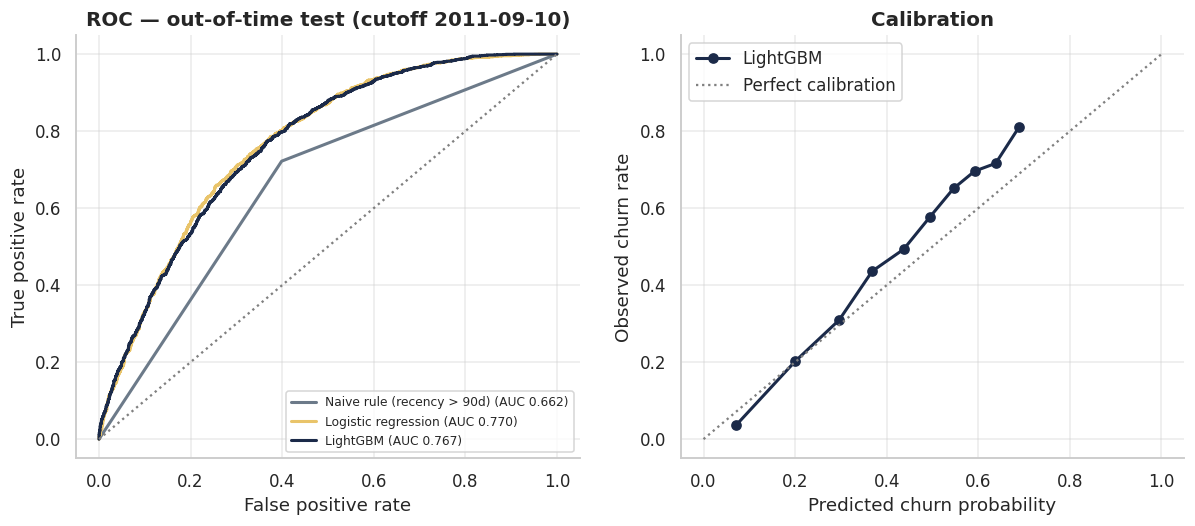

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for (name, s), col in zip(scores.items(), [PALETTE["slate"], PALETTE["amber"], PALETTE["navy"]]):
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, s):.3f})", color=col, lw=2)
axes[0].plot([0, 1], [0, 1], ls=":", color="grey")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC — out-of-time test (cutoff 2011-09-10)"); axes[0].legend(fontsize=8)

prob_true, prob_pred = calibration_curve(y_test, scores["LightGBM"], n_bins=10, strategy="quantile")
axes[1].plot(prob_pred, prob_true, marker="o", color=PALETTE["navy"], lw=2, label="LightGBM")
axes[1].plot([0, 1], [0, 1], ls=":", color="grey", label="Perfect calibration")
axes[1].set_xlabel("Predicted churn probability"); axes[1].set_ylabel("Observed churn rate")
axes[1].set_title("Calibration"); axes[1].legend()
viz.save(fig, "13_churn_model_roc_calibration")
plt.show()

Logistic regression and LightGBM are close on ROC-AUC. LightGBM is kept because
it wins on the metrics that matter for a retention campaign, which only
contacts the top of the list: **PR-AUC and top-decile lift**. It is also
shallow and regularised (selected by cross-validation above).

In [6]:
threshold = 0.5
pred = (scores["LightGBM"] >= threshold).astype(int)
print(classification_report(y_test, pred, target_names=["Retained", "Churned"], digits=3))

              precision    recall  f1-score   support

    Retained      0.675     0.745     0.708      2184
     Churned      0.706     0.631     0.666      2122

    accuracy                          0.689      4306
   macro avg      0.691     0.688     0.687      4306
weighted avg      0.690     0.689     0.688      4306



## 3. What drives churn? (SHAP)

In [7]:
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(X_test)
if isinstance(shap_values, list):
    shap_values = shap_values[1]

importance = (pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES)
              .sort_values(ascending=False))
season_shap = shap_values[:, FEATURES.index("days_to_dec1")]
print(f"days_to_dec1: mean |SHAP| {importance['days_to_dec1']:.3f}, "
      f"std across test customers {season_shap.std():.4f}")

days_to_dec1: mean |SHAP| 0.890, std across test customers 0.1412


`days_to_dec1` has the largest SHAP value, but it is the same for every
customer within a snapshot and its SHAP contribution barely varies between
customers (see the std above). It is **mostly a baseline shift** for the season:
it tells us *how much* churn to expect, not *which* customers will churn. The plot below shows
the behavioural drivers that rank customers against each other.

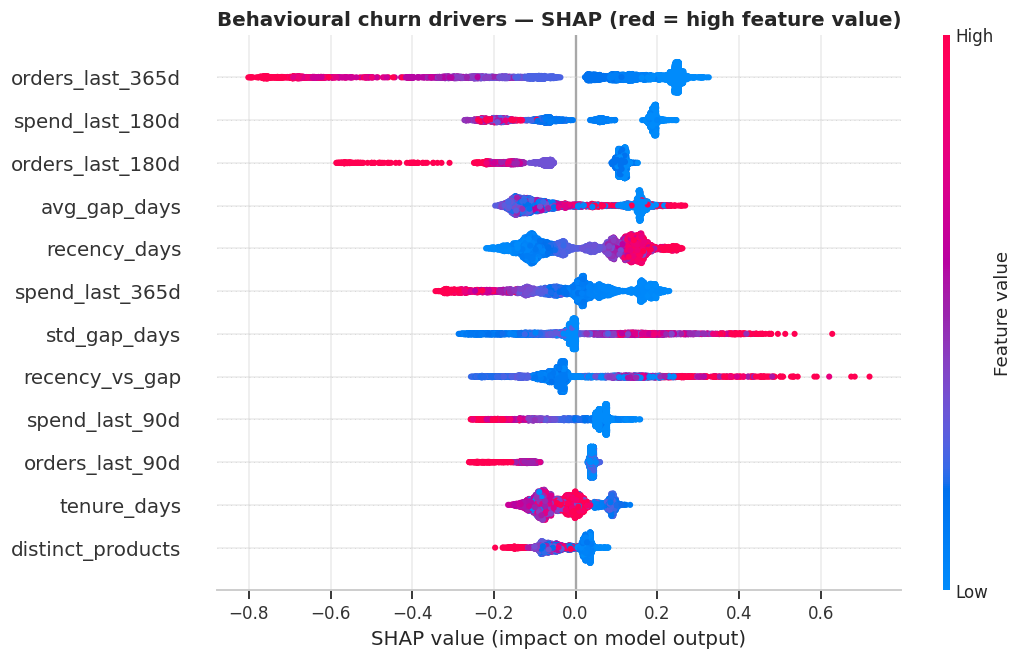

,mean |SHAP|
orders_last_365d,0.230
spend_last_180d,0.157
orders_last_180d,0.132
avg_gap_days,0.120
recency_days,0.115
spend_last_365d,0.105
std_gap_days,0.099
recency_vs_gap,0.093
spend_last_90d,0.075
orders_last_90d,0.060


In [8]:
behav = [f for f in FEATURES if f != "days_to_dec1"]
idx = [FEATURES.index(f) for f in behav]
plt.figure()
shap.summary_plot(shap_values[:, idx], X_test[behav], max_display=12, show=False, plot_size=(10, 6))
plt.title("Behavioural churn drivers — SHAP (red = high feature value)", fontweight="bold")
viz.save(plt.gcf(), "14_churn_shap_summary")
plt.show()

importance = importance.drop("days_to_dec1")
importance.head(10).round(3).to_frame("mean |SHAP|")

### Driver deep-dives

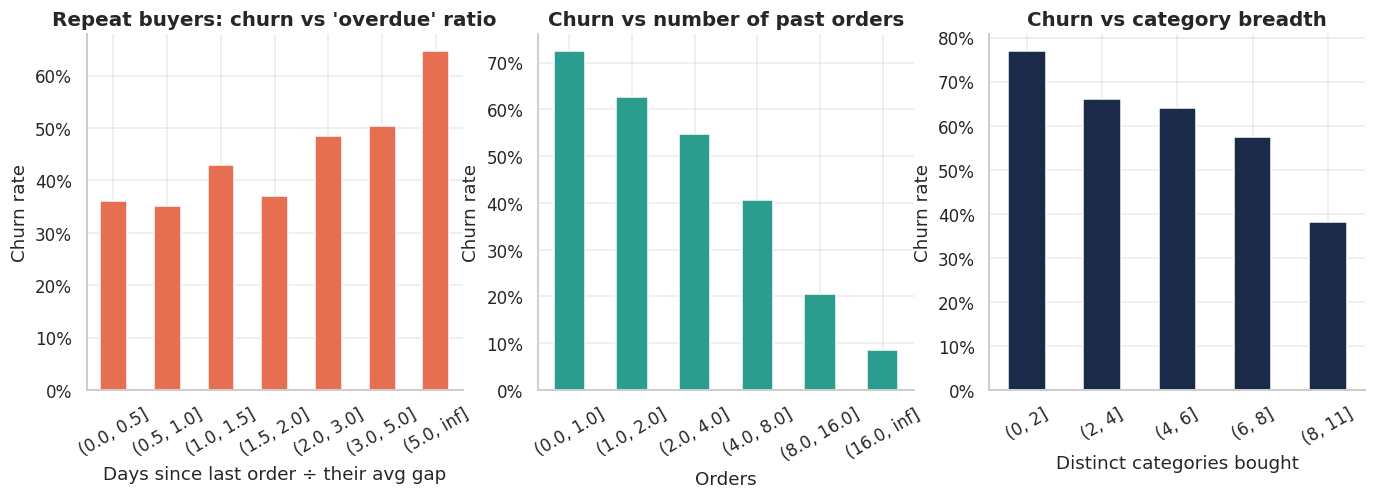

Churn: single-order customers 72.4% vs 8+ orders 18.5%
Repeat buyers >2× overdue vs their usual gap: 55.0% churn vs on-rhythm 35.1%


In [9]:
test_view = test.assign(p=scores["LightGBM"])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

repeat = test_view[test_view["frequency"] >= 2]
b = pd.cut(repeat["recency_vs_gap"], [0, 0.5, 1, 1.5, 2, 3, 5, np.inf])
repeat.groupby(b, observed=True)["churned"].mean().plot.bar(ax=axes[0], color=PALETTE["coral"])
axes[0].set_title("Repeat buyers: churn vs 'overdue' ratio"); axes[0].set_xlabel("Days since last order ÷ their avg gap")

b = pd.cut(test_view["frequency"], [0, 1, 2, 4, 8, 16, np.inf])
test_view.groupby(b, observed=True)["churned"].mean().plot.bar(ax=axes[1], color=PALETTE["teal"])
axes[1].set_title("Churn vs number of past orders"); axes[1].set_xlabel("Orders")

b = pd.cut(test_view["distinct_categories"], [0, 2, 4, 6, 8, 11])
test_view.groupby(b, observed=True)["churned"].mean().plot.bar(ax=axes[2], color=PALETTE["navy"])
axes[2].set_title("Churn vs category breadth"); axes[2].set_xlabel("Distinct categories bought")
for ax in axes:
    viz.pct_axis(ax); ax.tick_params(axis="x", rotation=30); ax.set_ylabel("Churn rate")
viz.save(fig, "15_churn_driver_deep_dives")
plt.show()

one_order = test_view.loc[test_view.frequency == 1, "churned"].mean()
loyal = test_view.loc[test_view.frequency >= 8, "churned"].mean()
overdue = repeat.loc[repeat.recency_vs_gap > 2, "churned"].mean()
on_rhythm = repeat.loc[repeat.recency_vs_gap <= 1, "churned"].mean()
print(f"Churn: single-order customers {one_order:.1%} vs 8+ orders {loyal:.1%}")
print(f"Repeat buyers >2× overdue vs their usual gap: {overdue:.1%} churn vs on-rhythm {on_rhythm:.1%}")

## 4. Does the model find the revenue? (back-test on the test snapshot)
If we had targeted the top 20% riskiest customers on 2011-09-10, how much of
the revenue that actually disappeared would we have covered?

Top 20% by value-at-risk captured 47.3% of lost revenue and 13.4% of churners


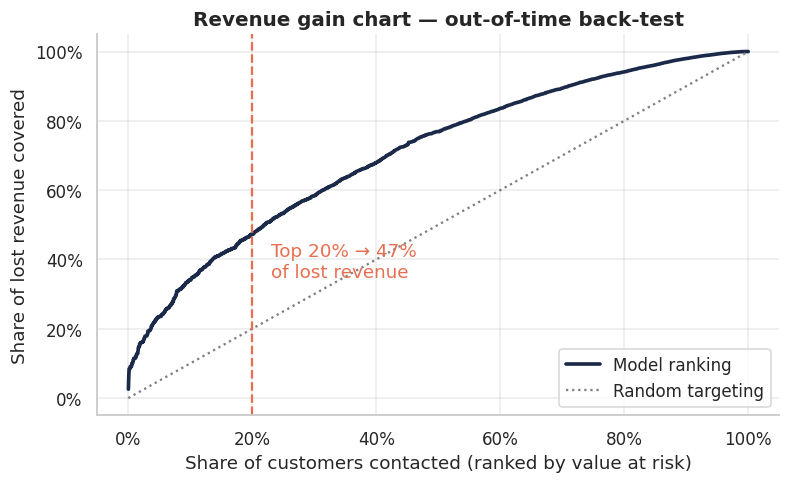

In [10]:
tv = test_view.copy()
tv["expected_quarterly_spend"] = tv["spend_last_365d"] / 4   # trailing 12 months, de-seasonalised
tv["lost_revenue"] = np.where(tv["churned"] == 1, tv["expected_quarterly_spend"], 0)
tv["value_at_risk"] = tv["p"] * tv["expected_quarterly_spend"]
tv = tv.sort_values("value_at_risk", ascending=False)
top20 = tv.head(int(len(tv) * 0.20))
capture = top20["lost_revenue"].sum() / tv["lost_revenue"].sum()
churn_capture = top20["churned"].sum() / tv["churned"].sum()
print(f"Top 20% by value-at-risk captured {capture:.1%} of lost revenue "
      f"and {churn_capture:.1%} of churners")

curve = tv["lost_revenue"].cumsum() / tv["lost_revenue"].sum()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.arange(1, len(tv) + 1) / len(tv), curve.values, color=PALETTE["navy"], lw=2.4, label="Model ranking")
ax.plot([0, 1], [0, 1], ls=":", color="grey", label="Random targeting")
ax.axvline(0.2, ls="--", color=PALETTE["coral"])
ax.text(0.23, 0.35, f"Top 20% → {capture:.0%}\nof lost revenue", color=PALETTE["coral"])
viz.pct_axis(ax, "x"); viz.pct_axis(ax, "y"); ax.legend(loc="lower right")
ax.set_xlabel("Share of customers contacted (ranked by value at risk)"); ax.set_ylabel("Share of lost revenue covered")
ax.set_title("Revenue gain chart — out-of-time back-test")
viz.save(fig, "16_revenue_gain_chart")
plt.show()

## 5. Score today's customers (as of 2011-12-10)
Retrain on all snapshots (train + test) and score every customer active in the last 12 months.

In [11]:
final_model = lgb.LGBMClassifier(**lgbm.get_params()).fit(
    pd.concat([X_train, X_test]), pd.concat([y_train, y_test]))
current = F.churn_features(sales, returns, products, C.SCORING_DATE)
current["churn_probability"] = final_model.predict_proba(current[FEATURES])[:, 1]
# Trailing-12-month spend, NOT the last 180 days x 2: the last 180 days include
# the Christmas peak and would overstate every customer's value.
current["annual_value"] = current["spend_last_365d"]
current["expected_quarterly_spend"] = current["annual_value"] / 4
current["revenue_at_risk_90d"] = current["churn_probability"] * current["expected_quarterly_spend"]
# Relative tiers: in December almost everyone has a high absolute probability
# (post-Christmas lull), so tiers rank customers against each other instead.
pct = current["churn_probability"].rank(pct=True)
current["risk_tier"] = np.select([pct > 0.70, pct > 0.30], ["High", "Medium"], "Low")
print(f"Mean predicted churn probability in this season: {current['churn_probability'].mean():.1%}")
print(current.groupby("risk_tier")["churn_probability"].agg(["min", "max", "mean"]).round(3))
print(f"Scored {len(current):,} active customers")
current["risk_tier"].value_counts().to_frame("customers")

Mean predicted churn probability in this season: 65.1%
             min    max   mean
risk_tier                     
High       0.831  0.945  0.879
Low        0.026  0.587  0.308
Medium     0.588  0.831  0.737
Scored 4,261 active customers


,customers
risk_tier,
Medium,1704
High,1279
Low,1278


## 6. Retention campaign: who to target and what it is worth

**Assumptions (explicit, adjustable in `src/config.py`):**
- A win-back offer retains **15%** of targeted customers who would otherwise churn
  (win-back rates commonly quoted in the 5–20% range; sensitivity shown below).
- Cost per targeted customer: **£10** (voucher + outreach).
- **Conservative horizon:** we only count the next 90 days of revenue (the same
  window the model predicts). In December many "churners" are pausing after
  Christmas rather than leaving for good, so annualising would overstate impact.
  If retained customers keep buying all year, the upside is up to ~4×.

Expected recovered revenue per customer = `p(churn) × quarterly value × save rate`,
where quarterly value = trailing-12-month spend ÷ 4.
Customers are ranked by that number, and we look for the point of diminishing returns.

,customers,recovered_revenue,share_of_recoverable,cost,net_benefit,roi
Top 5%,213,"£19,944",23%,"£2,130","£17,814",8.4x
Top 10%,426,"£28,903",33%,"£4,260","£24,643",5.8x
Top 20%,852,"£42,398",49%,"£8,520","£33,878",4.0x
Top 30%,"1,278","£52,882",61%,"£12,780","£40,102",3.1x
Top 50%,"2,130","£68,679",79%,"£21,300","£47,379",2.2x
Top 100%,"4,261","£86,735",100%,"£42,610","£44,125",1.0x


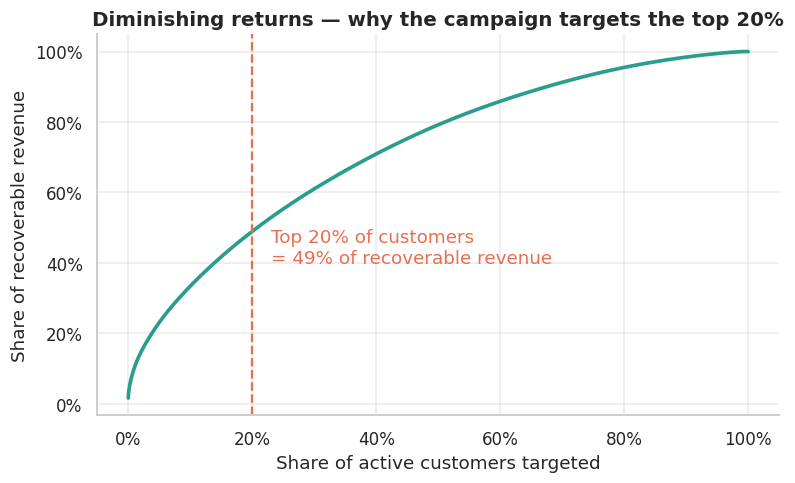

In [12]:
current["expected_recovery"] = (current["churn_probability"] * current["expected_quarterly_spend"]
                                * C.CAMPAIGN_SAVE_RATE)
ranked = current.sort_values("expected_recovery", ascending=False)
total_recoverable = ranked["expected_recovery"].sum()

def depth_row(share):
    n = int(round(len(ranked) * share))
    rec = ranked["expected_recovery"].head(n).sum()
    cost = n * C.CAMPAIGN_COST_PER_CUSTOMER
    return {"customers": n, "recovered_revenue": rec, "share_of_recoverable": rec / total_recoverable,
            "cost": cost, "net_benefit": rec - cost, "roi": (rec - cost) / cost}

depth = pd.DataFrame({f"Top {s:.0%}": depth_row(s) for s in [0.05, 0.10, 0.20, 0.30, 0.50, 1.00]}).T
display(depth.style.format({"customers": "{:,.0f}", "recovered_revenue": "£{:,.0f}",
                            "share_of_recoverable": "{:.0%}", "cost": "£{:,.0f}",
                            "net_benefit": "£{:,.0f}", "roi": "{:.1f}x"}))

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(1, len(ranked) + 1) / len(ranked)
ax.plot(x, ranked["expected_recovery"].cumsum() / total_recoverable, color=PALETTE["teal"], lw=2.4)
ax.axvline(0.2, ls="--", color=PALETTE["coral"])
ax.text(0.23, 0.4, f"Top 20% of customers\n= {depth.loc['Top 20%', 'share_of_recoverable']:.0%} of recoverable revenue",
        color=PALETTE["coral"])
viz.pct_axis(ax, "x"); viz.pct_axis(ax, "y")
ax.set_xlabel("Share of active customers targeted"); ax.set_ylabel("Share of recoverable revenue")
ax.set_title("Diminishing returns — why the campaign targets the top 20%")
viz.save(fig, "17_campaign_targeting_curve")
plt.show()

**Reading the table:** ROI is highest at the top of the list, while *net* benefit
keeps growing until roughly the top 50% and then falls as costs outrun returns.

**Recommendation: a two-tier campaign**
- **Tier 1 (top 20%):** personal outreach and a tailored offer — best ROI, roughly half of all recoverable revenue.
- **Tier 2 (next 30%):** low-cost automated win-back email.
- **Bottom 50%:** no paid campaign (expected recovery below cost).

In [13]:
TARGET_SHARE = 0.20
n_target = int(round(len(ranked) * TARGET_SHARE))
n_tier2 = int(round(len(ranked) * 0.50))
tier = pd.Series("No campaign", index=ranked.index)
tier.iloc[:n_tier2] = "Tier 2 - automated email"
tier.iloc[:n_target] = "Tier 1 - personal outreach"
current["campaign_tier"] = tier.reindex(current.index)
current["target_for_campaign"] = current["campaign_tier"].str.startswith("Tier 1")
plan = depth_row(TARGET_SHARE)

sens = {}
for rate in [0.05, 0.10, 0.15, 0.20]:
    rec = (ranked.head(n_target)["churn_probability"] * ranked.head(n_target)["expected_quarterly_spend"] * rate).sum()
    sens[f"{rate:.0%} save rate"] = {"recovered_revenue": rec, "net_benefit": rec - plan["cost"]}
display(pd.DataFrame(sens).T.style.format("£{:,.0f}"))

total_at_risk_90d = current["revenue_at_risk_90d"].sum()
high = current[current["risk_tier"] == "High"]
print(f"Expected revenue at risk in the next 90 days (all active customers): {C.CURRENCY}{total_at_risk_90d:,.0f}")
print(f"High-risk tier: {len(high):,} customers")
print(f"Tier 1 plan: target {plan['customers']:,} customers → recover {C.CURRENCY}{plan['recovered_revenue']:,.0f} "
      f"for {C.CURRENCY}{plan['cost']:,.0f} (net {C.CURRENCY}{plan['net_benefit']:,.0f}, ROI {plan['roi']:.1f}x)")
base = plan

,recovered_revenue,net_benefit
5% save rate,"£14,133","£5,613"
10% save rate,"£28,265","£19,745"
15% save rate,"£42,398","£33,878"
20% save rate,"£56,530","£48,010"


Expected revenue at risk in the next 90 days (all active customers): £578,236
High-risk tier: 1,279 customers
Tier 1 plan: target 852 customers → recover £42,398 for £8,520 (net £33,878, ROI 4.0x)


## 7. Combine RFM + churn into one customer table (feeds SQL & Power BI)

In [14]:
rfm = pd.read_csv(C.OUTPUTS_DIR / "rfm_segments.csv").set_index("customer_id")
insights = rfm.join(current[["churn_probability", "risk_tier", "expected_quarterly_spend",
                             "annual_value", "revenue_at_risk_90d", "target_for_campaign", "campaign_tier", "expected_recovery",
                             "recency_vs_gap", "distinct_categories"]], how="left")
insights["risk_tier"] = insights["risk_tier"].fillna("Lapsed (>12m)")
insights["target_for_campaign"] = insights["target_for_campaign"].fillna(False).astype(bool)
insights["campaign_tier"] = insights["campaign_tier"].fillna("No campaign")
insights = insights.reset_index()

matrix = pd.crosstab(insights["segment"], insights["risk_tier"])
display(matrix)

insights["distinct_categories"] = insights["distinct_categories"].astype("Int64")
insights.round(4).to_csv(C.PROCESSED_DIR / "customer_insights.csv", index=False)
print("Saved data/processed/customer_insights.csv")

io.update_metrics({
    "churn_rate_test": float(y_test.mean()),
    "auc_lgbm": float(results.loc["LightGBM", "ROC-AUC"]),
    "auc_logreg": float(results.loc["Logistic regression", "ROC-AUC"]),
    "auc_naive": float(results.loc["Naive rule (recency > 90d)", "ROC-AUC"]),
    "pr_auc_lgbm": float(results.loc["LightGBM", "PR-AUC"]),
    "top_decile_lift": float(results.loc["LightGBM", "Top-decile lift"]),
    "top20_lost_revenue_capture": float(capture),
    "churn_single_order": float(one_order), "churn_8plus_orders": float(loyal),
    "churn_overdue_2x": float(overdue), "churn_on_rhythm": float(on_rhythm),
    "active_customers_scored": int(len(current)),
    "high_risk_customers": int(len(high)),
    "revenue_at_risk_90d": float(total_at_risk_90d),
    "top_tier_revenue_at_risk_90d": float(ranked.head(n_target)["revenue_at_risk_90d"].sum()),
    "campaign_targeted": int(base["customers"]),
    "campaign_share_of_recoverable": float(base["share_of_recoverable"]),
    "two_tier_net_benefit": float(depth_row(0.50)["net_benefit"]),
    "total_recoverable_all": float(total_recoverable),
    "campaign_recovered": float(base["recovered_revenue"]),
    "campaign_cost": float(base["cost"]),
    "campaign_net": float(base["net_benefit"]),
    "campaign_roi": float(base["roi"]),
    "top_driver": importance.index[0], "second_driver": importance.index[1],
})

risk_tier,High,Lapsed (>12m),Low,Medium
segment,,,,
About to Sleep,328,0,0,55
At Risk,132,421,0,205
Can't Lose Them,10,28,0,34
Champions,4,0,672,152
Hibernating,356,1142,0,13
Loyal Customers,28,0,544,581
Need Attention,100,0,3,166
New Customers,19,0,0,35
Potential Loyalists,228,0,59,423


Saved data/processed/customer_insights.csv


{'gross_sales': 19643861.619999997,
 'returns_value': 716425.9700000001,
 'net_revenue': 18927435.65,
 'orders': 39516,
 'customers': 5852,
 'yoy_growth_jan_nov_2011': 0.02328228004888455,
 'q4_share_2010': 0.444756347650504,
 'share_products_for_80pct_revenue': 0.2125051082958725,
 'top20_customers_revenue_share': 0.7685092594770677,
 'share_customers_for_80pct_revenue': 0.2342127659574468,
 'one_time_buyer_share': 0.27648667122351334,
 'uk_share': 0.8552808859585113,
 'aov_uk': 464.3217822794606,
 'aov_intl': 853.1939525810324,
 'retention_m1': 0.20989927377323506,
 'retention_m3': 0.21723701495880113,
 'retention_m12': 0.18266340020354108,
 'champions_loyal_customer_share': 0.33851674641148327,
 'champions_loyal_revenue_share': 0.801273394121218,
 'slipping_customers': 1213,
 'slipping_lifetime_revenue': 1637286.21,
 'churn_rate_test': 0.4928007431490943,
 'auc_lgbm': 0.7671539307378139,
 'auc_logreg': 0.770004108364146,
 'auc_naive': 0.6615754454467931,
 'pr_auc_lgbm': 0.7309287567